# 14 · Checkpoint: the single support desk
Level L2 · Part 2 · core · ~50 min · builds on 09, 10, 13

## Goal
Run the whole single-agent desk as one graph: it remembers the customer, answers from the policy and the order system, cites the
policy, and pauses a refund for a person. Then check the requirements, the way lesson 08 did for v1.

## Why it matters
Memory, retrieval and approval each work alone. Together they interact: a remembered fact can override a lookup, and a refund can be
requested from a policy answer the customer never saw. The desk is the place where these meet, so it is where you test them.

## The idea
The desk is the graph from lesson 07 with three additions: a `recall` node that reads the customer's facts before the model answers,
a `search_guide` tool over the policy (lesson 10), and an `approval` node that pauses the refund (lesson 13). The model decides which
tool to use; the graph decides what a refund needs.

## Picture
`show_mermaid` is a course helper from `graph_view.py`: it draws the text diagram below as a picture (or prints the text when the
drawing service is not reachable). Read the arrows as the routes a run can take. The model (yellow) chooses the route; the other
boxes are ordinary code.

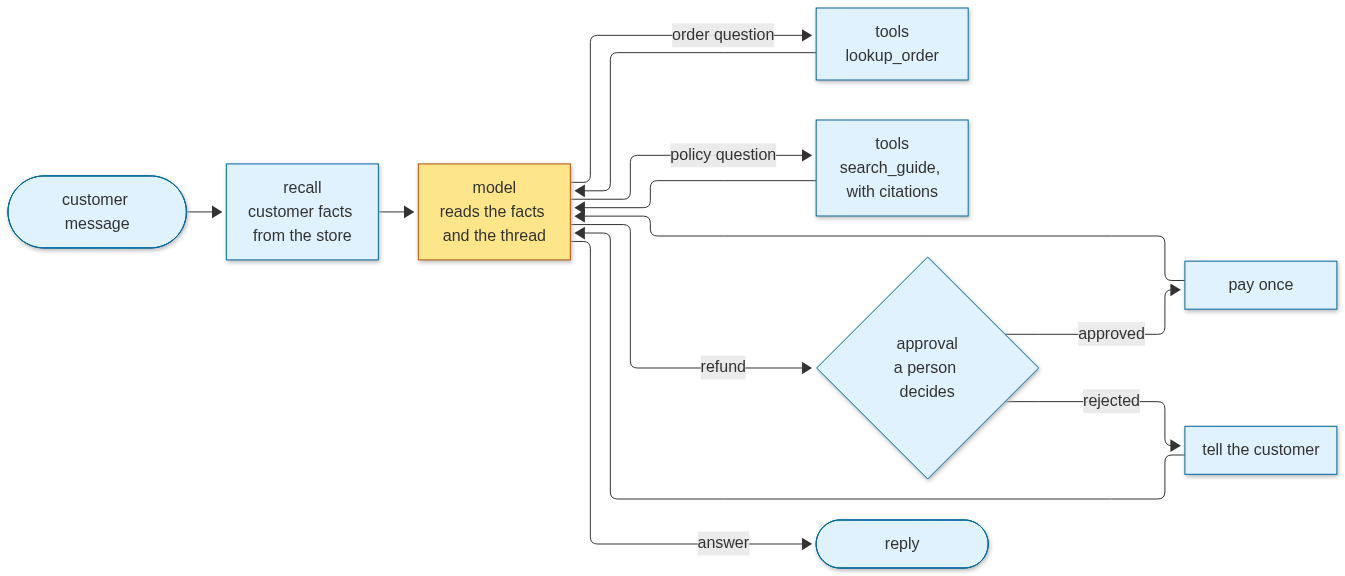

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  U(["customer message"]) --> R["recall<br/>customer facts from the store"]
  R --> M["model<br/>reads the facts and the thread"]
  M -->|order question| L["tools<br/>lookup_order"] --> M
  M -->|policy question| S["tools<br/>search_guide, with citations"] --> M
  M -->|refund| A{"approval<br/>a person decides"}
  A -->|approved| P["pay once"] --> M
  A -->|rejected| J["tell the customer"] --> M
  M -->|answer| E(["reply"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class U,R,L,S,A,P,J,E code
""")

## Requirements
The single-agent desk must:

1. answer order questions from `lookup_order`, never from memory;
2. answer policy questions from the guide, and cite the chunk it used;
3. remember a customer's size across two threads, and never store a card number;
4. pause any refund for a person, pay only after the decision, and pay once;
5. end every run with a reply within eight model calls, so a loop cannot run on.

## Build it
**Step 1 · the parts (no call).** The order rows, the policy chunks, the memory store and the refund ledger. These are the same data
and rules as lessons 08 to 13; each is small.

In [2]:
import json
import operator
import re
from pathlib import Path
from typing import Annotated, Literal

from langchain_core.tools import tool
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.store.memory import InMemoryStore
from pydantic import BaseModel, ConfigDict, Field
from typing_extensions import TypedDict

DATA = json.loads((Path("../../../data") / "support_eval.json").read_text())
ORDERS = DATA["world"]["orders"]
TEXT = (Path("../../../data") / "ftc_30_day_rule.txt").read_text(encoding="utf-8")
CHUNKS = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=80).split_text(TEXT)
PAID: list = []  # what the money has really done
STORE = InMemoryStore()
CARD = re.compile(r"\b(?:\d[ -]?){13,19}\b")
print(len(ORDERS), "orders ·", len(CHUNKS), "policy chunks ·", len(PAID), "payments so far")

12 orders · 67 policy chunks · 0 payments so far


**Step 2 · the tools (no call).** `lookup_order` returns the order row. `search_guide` returns numbered chunks. `issue_refund` is the
write: it is never run by the model; the approval node runs it after a person decides.

In [3]:
class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late. Use it when the customer gives an order number."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


@tool
def search_guide(query: str) -> str:
    """Search the FTC mail-order guide for rules about delivery, refunds or returns. Returns numbered chunks."""
    words = set(re.findall(r"[a-z]{4,}", query.lower()))
    ranked = sorted(range(len(CHUNKS)), key=lambda i: -len(words & set(re.findall(r"[a-z]{4,}", CHUNKS[i].lower()))))
    return "\n".join(f"[chunk {i}] {CHUNKS[i]}" for i in ranked[:3])


@tool
def issue_refund(order_id: str, amount_usd: float) -> str:
    """Request a refund. A person must approve it first; the desk pays only after that decision."""
    return "refund requested; a person will decide"  # the model's request only; the approval node does the payment


TOOLS = [lookup_order, search_guide, issue_refund]
print(lookup_order.invoke({"order_id": "1003"}))
print(search_guide.invoke({"query": "late delivery refund"})[:120])

{'status': 'lost', 'days_late': 9, 'total': 89.5}
[chunk 9] What You Must Do If You Learn You Cannot Ship on Time

When you learn that you cannot ship on time, you must d


**Step 3 · the graph (no call yet).** `recall` reads the customer's facts from the store. `model` answers or asks for a tool. A refund
request goes to `approval`, which pauses for a person. `pay` runs only after an approval, and records the payment under the thread id, so a
repeat cannot pay twice. The state holds the messages, the facts the store gave back, the refund waiting for a person and the decision.

In [4]:
from langchain_core.messages import HumanMessage, ToolMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.prebuilt import ToolNode
from langgraph.types import Command, interrupt
from langchain_core.runnables import RunnableConfig


class DeskState(TypedDict):
    messages: Annotated[list, operator.add]
    facts: list
    refund: dict  # the refund the model asked for, waiting for a person
    decision: str  # "approve" or "reject", from a person


def recall(state: DeskState, config: RunnableConfig, *, store) -> dict:
    customer = config["configurable"]["customer_id"]
    return {"facts": [item.value["fact"] for item in store.search(("customer", customer))]}


def model_step(state: DeskState, llm_with_tools) -> dict:
    context = HumanMessage(content=f"Known facts about this customer: {state['facts'] or 'none'}. "
                                   "Answer order facts only from lookup_order. Cite policy chunks by number.")
    return {"messages": [llm_with_tools.invoke([context] + state["messages"])]}

**Step 3b · the routes (no call).** After the model, the route depends on what it asked for: no tool call ends the run, a refund goes
to the person, and any other tool goes back to the model with its answer.

In [5]:
def route_model(state: DeskState) -> Literal["tools", "approval", "__end__"]:
    last = state["messages"][-1]
    if not last.tool_calls:
        return END
    if any(c["name"] == "issue_refund" for c in last.tool_calls):
        return "approval"
    return "tools"


def approval(state: DeskState) -> dict:
    last = state["messages"][-1]
    call = next(c for c in last.tool_calls if c["name"] == "issue_refund")
    decision = interrupt({"question": "Approve this refund?", **call["args"]})  # the run pauses here, saved
    return {"refund": dict(call["args"]), "decision": decision["decision"],
            "messages": [ToolMessage(content=f"decision: {decision['decision']}", tool_call_id=call["id"])]}


def pay(state: DeskState, config: RunnableConfig) -> dict:
    key = config["configurable"]["thread_id"]  # the thread id is the idempotency key
    if state["decision"] == "approve" and not any(p[0] == key for p in PAID):
        PAID.append((key, state["refund"]["amount_usd"]))  # the payment happens once per key
    return {}


def route_decision(state: DeskState) -> Literal["pay", "__end__"]:
    return "pay" if state["decision"] == "approve" else END


print("approve ->", route_decision({"decision": "approve"}), "· reject ->", route_decision({"decision": "reject"}))  # __end__ = the run stops

approve -> pay · reject -> __end__


**Step 3c · the wiring (no call).** `build_desk` adds the nodes and the edges, then compiles the graph with a checkpointer (it saves
every step) and the store (it keeps facts across threads).

In [6]:
def build_desk(llm, store, saver):
    llm_with_tools = llm.bind_tools(TOOLS)
    g = StateGraph(DeskState)
    g.add_node("recall", recall)
    g.add_node("model", lambda s: model_step(s, llm_with_tools))
    g.add_node("tools", ToolNode([lookup_order, search_guide]))
    g.add_node("approval", approval)
    g.add_node("pay", pay)
    g.add_edge(START, "recall").add_edge("recall", "model")
    g.add_conditional_edges("model", route_model, {"tools": "tools", "approval": "approval", END: END})
    g.add_edge("tools", "model")
    g.add_conditional_edges("approval", route_decision, {"pay": "pay", END: END})
    g.add_edge("pay", END)
    return g.compile(checkpointer=saver, store=store)

**Step 4 · the run (uses the model: 5 calls in all, 2 for the day-two thread and 3 for the refund).** The size was saved on an earlier
visit, so it is written straight into the store here. Day two is a new thread: the customer asks about a jacket in that size and about the
guide. The refund run asks for a refund: it pauses, a person approves it, and the payment is recorded once. The Reference solution below
checks the result.

LLM mode: replay (14_checkpoint-single-desk.yaml)


Gemini on Vertex AI · API key loaded: True


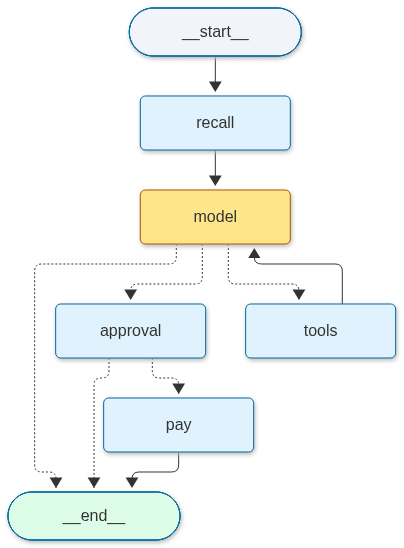

recalled: ['size M']
answer: Regarding your order 1003, it is currently marked as lost and is 9 days late. I do not have information on current inventory or jacket availability in size M.

Regarding refunds for late delivery, the FTC guide states that if a business cannot ship an order or provide a delay notification within the
paused for: ['Approve this refund?'] · money moved: []
money moved: [('refund-1003', 89.5)]


In [7]:
import llm_replay  # course helper: records and replays model calls so the lesson runs offline (not part of LangGraph)
llm_replay.start("14_checkpoint-single-desk")

from llm_setup import get_llm  # course helper: the course's model setup
from graph_view import show_graph  # course helper: draws the compiled graph as a picture

llm = get_llm()
desk = build_desk(llm, STORE, InMemorySaver())
show_graph(desk, model_nodes=("model",))

STORE.put(("customer", "1003"), "size", {"fact": "size M"})  # saved on an earlier visit
day2 = desk.invoke({"messages": [HumanMessage(content="Order 1003 still has not arrived. Do you have a jacket in my size? Also, what does the guide say about refunds for late delivery?")],
                    "facts": [], "refund": {}, "decision": ""},
                   config={"configurable": {"thread_id": "day-2", "customer_id": "1003"}, "recursion_limit": 8})
print("recalled:", day2["facts"])
print("answer:", day2["messages"][-1].text[:300])

CFG = {"configurable": {"thread_id": "refund-1003", "customer_id": "1003"}, "recursion_limit": 8}
paused = desk.invoke({"messages": [HumanMessage(content="Order 1003 was lost. Please refund the 89.50 I paid.")],
                      "facts": [], "refund": {}, "decision": ""}, CFG)
print("paused for:", [i.value["question"] for i in paused.get("__interrupt__", [])], "· money moved:", PAID)
desk.invoke(Command(resume={"decision": "approve"}), CFG)
desk.invoke(Command(resume={"decision": "approve"}), CFG)  # a repeated resume must not pay again
print("money moved:", PAID)
llm_replay.stop()  # the last model call of this lesson

## Reference solution
Each requirement is checked below. The checks run on the saved state and the payment record, so they can be repeated without a model.

In [8]:
checks = {
    "1 · answers the order from lookup_order": any(getattr(m, "name", "") == "lookup_order" for m in day2["messages"] if m.type == "tool"),
    "2 · cites a policy chunk": "chunk" in day2["messages"][-1].text.lower(),
    "3 · remembers the size across threads": "size M" in day2["facts"],
    "3 · the card-number rule holds": not CARD.search(" ".join(day2["facts"])),
    "4 · the refund was paid once": len([p for p in PAID if p[0] == "refund-1003"]) == 1,
    "5 · ended in a reply within eight model calls": sum(m.type == "ai" for m in day2["messages"]) <= 8 and not day2["messages"][-1].tool_calls,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - 1 · answers the order from lookup_order
PASS - 2 · cites a policy chunk
PASS - 3 · remembers the size across threads
PASS - 3 · the card-number rule holds
PASS - 4 · the refund was paid once
PASS - 5 · ended in a reply within eight model calls


## Common mistakes
1. **Invoking the desk without a thread id.** The checkpointer saves each step under the thread id, so a run without one cannot be
   saved or resumed. The fix: put `thread_id` in the config.

In [9]:
try:
    desk.invoke({"messages": [HumanMessage(content="Where is order 1001?")], "facts": [], "refund": {}, "decision": ""})  # no config
except Exception as err:
    print(type(err).__name__, "-", str(err).splitlines()[0])

ValueError - Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id


2. **Leaving out `customer_id`.** The `recall` node reads it from the config, so the run fails before the model is called. The fix:
   send the customer id with the thread id.

In [10]:
try:
    desk.invoke({"messages": [HumanMessage(content="Where is order 1001?")], "facts": [], "refund": {}, "decision": ""},
                config={"configurable": {"thread_id": "no-customer"}})  # the customer id is missing
except Exception as err:
    print(type(err).__name__, "-", str(err).splitlines()[0])

KeyError - 'customer_id'


3. **Calling the desk done after one good run.** One run is one case. Run all five checks after each change, and add a case
   whenever a customer finds a new failure.

## What just happened
- The day-two thread recalled `['size M']` from the store and used two model calls: the first asked for two tools, the second wrote the reply.
- The refund run paused for `Approve this refund?` with no money moved (`[]`), then the approval paid `89.5` once for `refund-1003`.
- The repeated resume did not pay again: the money list still holds one payment.
- All five checks printed PASS, and the two mistake cells printed `ValueError` and `KeyError`.

## Key terms
- **Checkpointer** — the saver that stores each step of a run under its thread id, so a paused run can resume later.
- **Thread id** — the id that ties together every saved step of one run or conversation.
- **interrupt()** — pauses a node and saves the run; the value it is resumed with comes back to the node.
- **Command(resume=...)** — the call that resumes a paused run with a person's decision.
- **Store** — the place for facts that outlive one thread, such as the customer's size.
- **Recursion limit** — the cap on the graph steps in one run.
- **Idempotency key** — an id that makes a repeated action happen once; here, the thread id.

## At work
- The single-agent desk is the thing most teams ship first. Its three parts are where most incidents start: memory that is wrong, a
  policy answer without a source, and a refund without a decision → lesson 34 (security and guardrails).
- The pause is a row in a store; the payment is a second row keyed by the thread. Teams check both before they show a refund as done → lesson 35.
- A checkpoint is the release gate for a single agent. The checks above are what a team runs before a change goes out → lesson 32.

## Recap
- The desk is one graph: recall, model, tools, approval, pay.
- Each requirement has a check that runs without a person.
- A refund waits for a decision, and the payment is recorded once per thread.

**Interview:** "Walk me through how a single agent handles a refund from a returning customer." Strong answer: "It recalls the customer's
saved facts, looks up the order with a tool, and cites the policy. A refund request pauses for a person; the payment runs after the
decision and is recorded under the thread id so it happens once."